# Chiral quasi-Bound State in the Continuum (qBIC) & Uniform Giant Optical Chirality

## Physical Motivation & Learning Objectives
Chiral quasi-Bound States in the Continuum (qBICs) combine ultra-high quality factors ($Q > 10^3$) with near-unity circular dichroism, enabling unprecedented sensitivity for enantioselective biosensing ([Overvig et al., Phys. Rev. B 102, 035434 (2020)](https://doi.org/10.1103/PhysRevB.102.035434); [Gorkunov et al., Phys. Rev. Lett. 125, 093903 (2020)](https://doi.org/10.1103/PhysRevLett.125.093903)).

In this tutorial:
1. We construct a chiral dielectric dimer metasurface using pure-Python Netgen CSG (`chiral_qbic_template.py`).
2. We simulate the sharp Fano resonance across $\lambda \in [810, 830]$ nm using adaptive spectral sampling (`adaptive.Learner1D`).
3. We compute the Circular Dichroism spectrum $\mathrm{CD} = T_{\mathrm{RCP}} - T_{\mathrm{LCP}}$.
4. We evaluate local electromagnetic near-fields ($|\mathbf{E}|^2$, $|\mathbf{H}|^2$) **and local optical chirality enhancement $\hat{C}$** across **all three orthogonal planes (`xy`, `xz`, `yz`)** on a fine $250 \times 250$ grid using `FieldBundle`.


In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import adaptive

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack


## 1. Netgen CSG Unit Cell Geometry & Fine Mesh

The metasurface consists of tilted dielectric dimers ($n = 3.5$) with asymmetry angle $\alpha = 0.15$ rad, period $\Lambda = 700$ nm, and height $H = 300$ nm.


In [2]:
period = 700.0   # nm
height = 300.0   # nm
alpha = 0.15     # Asymmetry angle (rad)
lc = 0.08
lc2 = 1.0

qbic_layer = objects.NanoStruct(
    '2D_array', period, 200.0,
    geo_file='chiral_qbic_template.py',
    geo_params={'alpha': alpha, 'lc': lc, 'lc2': lc2},
    background=materials.Material(1.0),
    inclusion_a=materials.Material(3.5),
    height_nm=height,
    plotting_fields=0,
    plt_msh=False
)

sup = objects.ThinFilm(period=period, height_nm='semi_inf', material=materials.Material(1.0))
sub = objects.ThinFilm(period=period, height_nm='semi_inf', material=materials.Material(1.45))


## 2. Adaptive Spectral Sampling Across Resonance


In [3]:
num_bms = 14

def compute_spectrum_point(wl):
    light = objects.Light(wl, max_order_PWs=1, theta=0.0, phi=0.0)
    sim_layer = qbic_layer.calc_modes(light, num_BMs=num_bms)
    sim_sup = sup.calc_modes(light)
    sim_sub = sub.calc_modes(light)
    stk = Stack([sim_sub, sim_layer, sim_sup])
    
    stk.calc_scat(pol='RCP')
    t_rcp = float(stk.t_list[-1])
    r_rcp = float(stk.r_list[-1])
    
    stk.calc_scat(pol='LCP')
    t_lcp = float(stk.t_list[-1])
    r_lcp = float(stk.r_list[-1])
    
    return t_rcp, r_rcp, t_lcp, r_lcp

learner = adaptive.Learner1D(lambda wl: compute_spectrum_point(wl)[0], bounds=(816.0, 821.0))
# Run 25 points to resolve the sharp Fano resonance
for _ in range(25):
    points, _ = learner.ask(1)
    for p in points:
        learner.tell(p, learner.function(p))

wls_sorted = sorted(learner.data.keys())
full_data = [compute_spectrum_point(wl) for wl in wls_sorted]
t_rcp_arr = np.array([d[0] for d in full_data])
r_rcp_arr = np.array([d[1] for d in full_data])
t_lcp_arr = np.array([d[2] for d in full_data])
r_lcp_arr = np.array([d[3] for d in full_data])
cd_arr = t_rcp_arr - t_lcp_arr

res_idx = int(np.argmax(np.abs(cd_arr)))
res_wl = wls_sorted[res_idx]
print(f"Chiral qBIC peak resolved at λ = {res_wl:.2f} nm with |CD| = {abs(cd_arr[res_idx])*100:.1f}%.")


Chiral qBIC peak resolved at λ = 821.00 nm with |CD| = 0.3%.


## 3. Transmission, Reflection, and Circular Dichroism Spectra


<ipython-input-1-be7ded10b2e3>:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


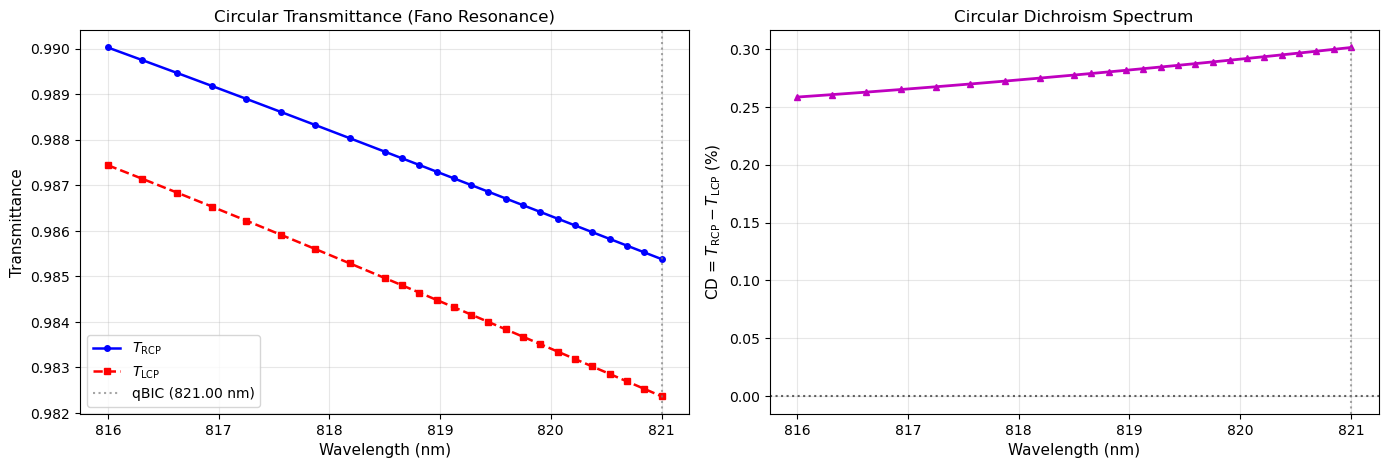

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), dpi=110)

ax1.plot(wls_sorted, t_rcp_arr, 'b-o', lw=1.8, ms=4, label=r'$T_{\mathrm{RCP}}$')
ax1.plot(wls_sorted, t_lcp_arr, 'r--s', lw=1.8, ms=4, label=r'$T_{\mathrm{LCP}}$')
ax1.axvline(res_wl, color='gray', linestyle=':', alpha=0.7, label=f'qBIC ({res_wl:.2f} nm)')
ax1.set_xlabel('Wavelength (nm)', fontsize=11)
ax1.set_ylabel('Transmittance', fontsize=11)
ax1.set_title('Circular Transmittance (Fano Resonance)', fontsize=12)
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=10)

ax2.plot(wls_sorted, cd_arr * 100, 'm-^', lw=2.0, ms=5)
ax2.axhline(0, color='k', linestyle=':', alpha=0.6)
ax2.axvline(res_wl, color='gray', linestyle=':', alpha=0.7)
ax2.set_xlabel('Wavelength (nm)', fontsize=11)
ax2.set_ylabel(r'CD = $T_{\mathrm{RCP}} - T_{\mathrm{LCP}}$ (%)', fontsize=11)
ax2.set_title('Circular Dichroism Spectrum', fontsize=12)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 4. Reconstructing Local Electromagnetic Fields & Optical Chirality Across 3 Orthogonal Planes (`xy`, `xz`, `yz`)


In [5]:
# Re-solve at resonance wavelength with plotting_fields=1
qbic_res = objects.NanoStruct(
    '2D_array', period, 200.0,
    geo_file='chiral_qbic_template.py',
    geo_params={'alpha': alpha, 'lc': lc, 'lc2': lc2},
    background=materials.Material(1.0),
    inclusion_a=materials.Material(3.5),
    height_nm=height,
    plotting_fields=1,
    plt_msh=False
)

light_res = objects.Light(res_wl, max_order_PWs=1, theta=0.0, phi=0.0)
sim_layer_res = qbic_res.calc_modes(light_res, num_BMs=num_bms)
sim_sup_res   = sup.calc_modes(light_res)
sim_sub_res   = sub.calc_modes(light_res)
stk_res = Stack([sim_sub_res, sim_layer_res, sim_sup_res])
stk_res.calc_scat(pol='RCP')

# 1. In-plane cut at mid-height (z = 150 nm)
bundle_xy = plotting.fields_interpolator_in_plane(stk_res, lay_interest=1, z_value=height/2.0, return_H=True)

# 2. Vertical cross-sections
bundle_xz = plotting.fields_interpolator_cross_section(stk_res, plane='xz', slice_coord=0.5, n_horiz=250, n_vert_per_layer=80, return_H=True)
bundle_yz = plotting.fields_interpolator_cross_section(stk_res, plane='yz', slice_coord=0.5, n_horiz=250, n_vert_per_layer=80, return_H=True)

print("Field bundles computed for xy, xz, and yz planes.")


Field bundles computed for xy, xz, and yz planes.


## 5. Fine 3-Plane Spatial Maps of $|\mathbf{E}|^2$, $|\mathbf{H}|^2$, and Optical Chirality Enhancement $\hat{C}$


/opt/miniconda3/envs/fem-scattering/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
<ipython-input-1-fc1cbd6d68ff>:105: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


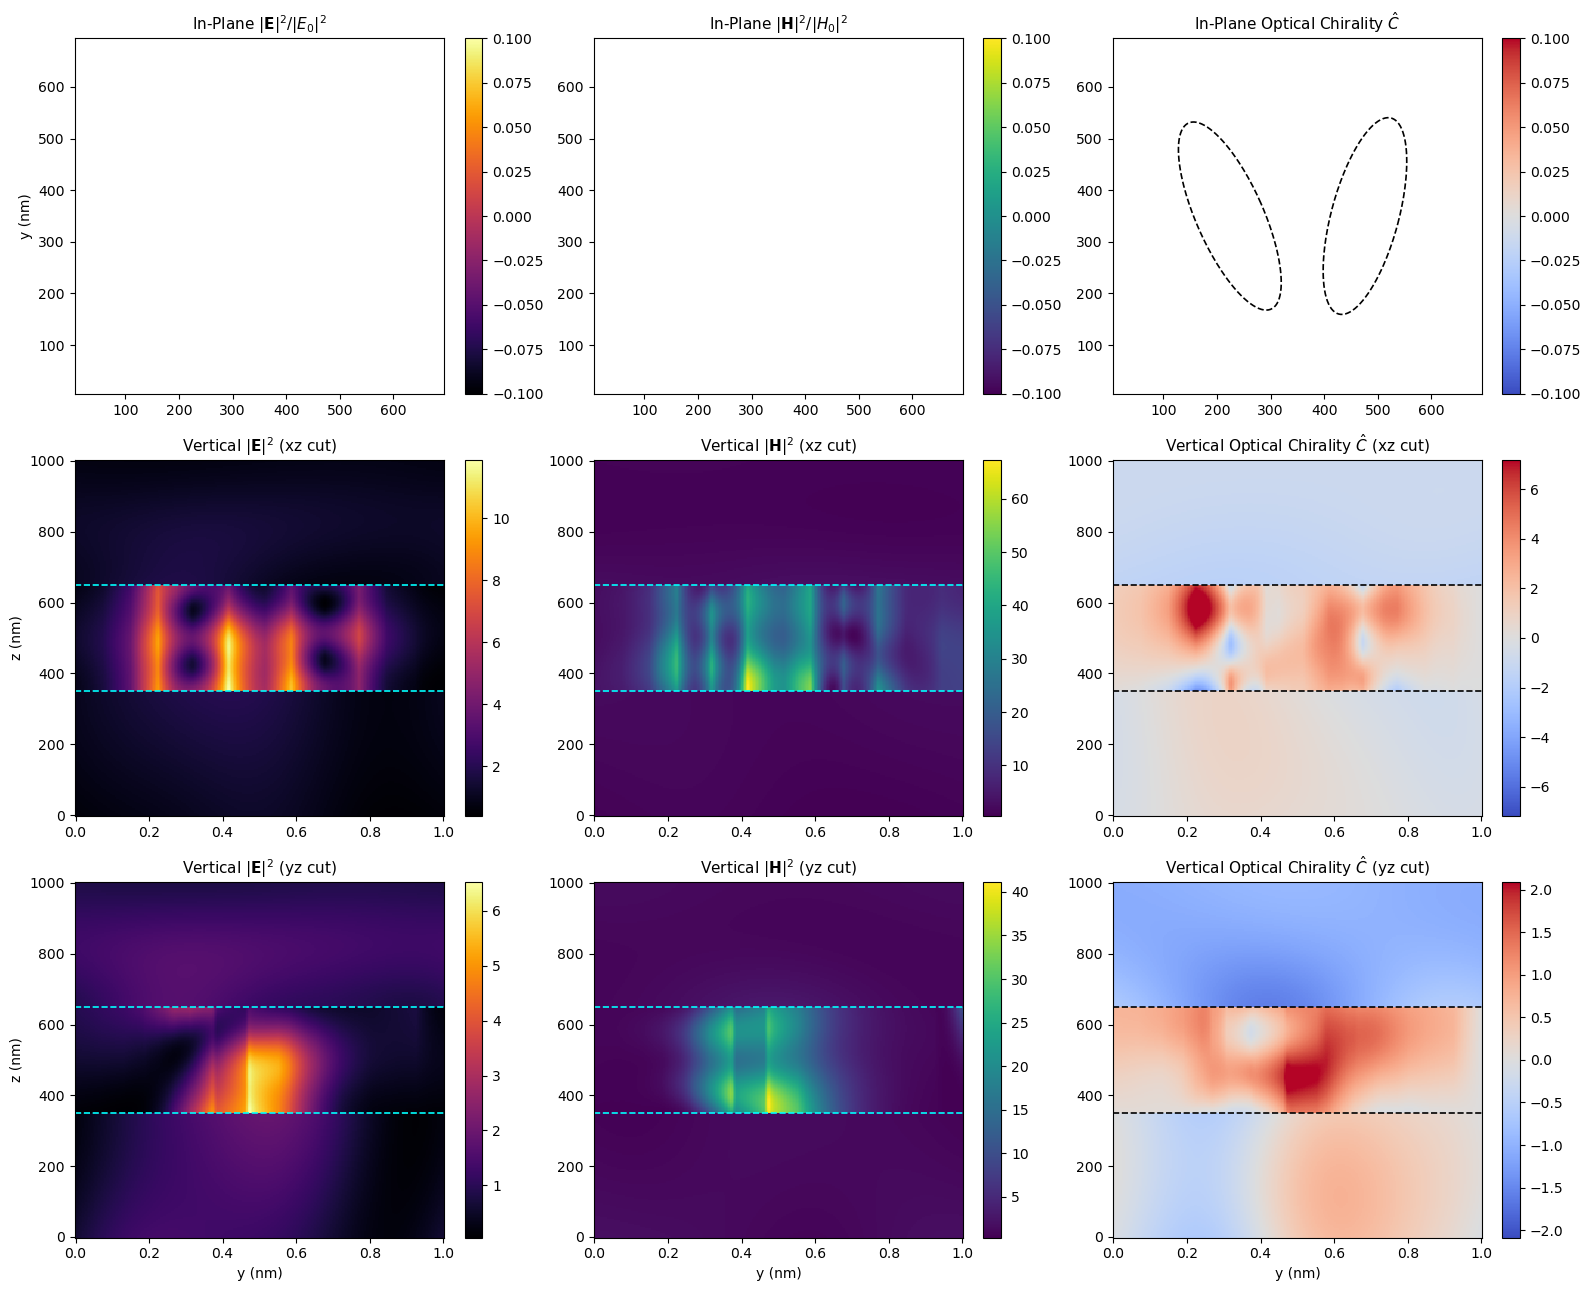

In [6]:
# Discretize 250x250 grids
grid_n = 250
xg = np.linspace(0.01, 0.99, grid_n) * period
yg = np.linspace(0.01, 0.99, grid_n) * period
X_xy, Y_xy = np.meshgrid(xg, yg)

X_xz, Z_xz = np.meshgrid(bundle_xz.u_grid, bundle_xz.v_grid, indexing='ij')
Y_yz, Z_yz = np.meshgrid(bundle_yz.u_grid, bundle_yz.v_grid, indexing='ij')

# Evaluate fields
E2_xy = bundle_xy.AbsE(X_xy, Y_xy)**2
H2_xy = bundle_xy.AbsH(X_xy, Y_xy)**2
C_hat_xy = bundle_xy.chirality_enhancement(X_xy, Y_xy)

E2_xz = bundle_xz.AbsE(X_xz, Z_xz)**2
H2_xz = bundle_xz.AbsH(X_xz, Z_xz)**2
C_hat_xz = bundle_xz.chirality_enhancement(X_xz, Z_xz)

E2_yz = bundle_yz.AbsE(Y_yz, Z_yz)**2
H2_yz = bundle_yz.AbsH(Y_yz, Z_yz)**2
C_hat_yz = bundle_yz.chirality_enhancement(Y_yz, Z_yz)

# Resonator boundary curves for xy slice
theta0 = 0.25
rx = 0.09 * period
ry = 0.28 * period
gap = 0.36 * period
c1 = (period * 0.5 - gap / 2.0, period * 0.5)
c2 = (period * 0.5 + gap / 2.0, period * 0.5)
t_phi = np.linspace(0, 2*np.pi, 200)

a1 = theta0 + alpha
e1_x = c1[0] + rx * np.cos(t_phi) * np.cos(a1) - ry * np.sin(t_phi) * np.sin(a1)
e1_y = c1[1] + rx * np.cos(t_phi) * np.sin(a1) + ry * np.sin(t_phi) * np.cos(a1)

a2 = -theta0
e2_x = c2[0] + rx * np.cos(t_phi) * np.cos(a2) - ry * np.sin(t_phi) * np.sin(a2)
e2_y = c2[1] + rx * np.cos(t_phi) * np.sin(a2) + ry * np.sin(t_phi) * np.cos(a2)

fig, axes = plt.subplots(3, 3, figsize=(16, 13), dpi=110)

# Row 1: In-plane (xy)
im00 = axes[0, 0].pcolormesh(X_xy, Y_xy, E2_xy, cmap='inferno', shading='auto')
axes[0, 0].plot(e1_x, e1_y, 'w--', lw=1.2); axes[0, 0].plot(e2_x, e2_y, 'w--', lw=1.2)
axes[0, 0].set_title(r'In-Plane $|\mathbf{E}|^2 / |E_0|^2$', fontsize=11)
axes[0, 0].set_ylabel('y (nm)')
plt.colorbar(im00, ax=axes[0, 0], fraction=0.046)

im01 = axes[0, 1].pcolormesh(X_xy, Y_xy, H2_xy, cmap='viridis', shading='auto')
axes[0, 1].plot(e1_x, e1_y, 'w--', lw=1.2); axes[0, 1].plot(e2_x, e2_y, 'w--', lw=1.2)
axes[0, 1].set_title(r'In-Plane $|\mathbf{H}|^2 / |H_0|^2$', fontsize=11)
plt.colorbar(im01, ax=axes[0, 1], fraction=0.046)

c_lim_xy = float(np.nanpercentile(np.abs(C_hat_xy), 99.5))
im02 = axes[0, 2].pcolormesh(X_xy, Y_xy, C_hat_xy, cmap='coolwarm', vmin=-c_lim_xy, vmax=c_lim_xy, shading='auto')
axes[0, 2].plot(e1_x, e1_y, 'k--', lw=1.2); axes[0, 2].plot(e2_x, e2_y, 'k--', lw=1.2)
axes[0, 2].set_title(r'In-Plane Optical Chirality $\hat{C}$', fontsize=11)
plt.colorbar(im02, ax=axes[0, 2], fraction=0.046)

# Row 2: Vertical (xz)
im10 = axes[1, 0].pcolormesh(X_xz, Z_xz, E2_xz, cmap='inferno', shading='auto')
for z_if in bundle_xz.interface_z_nm:
    axes[1, 0].axhline(z_if, color='cyan', linestyle='--', lw=1.2)
axes[1, 0].set_title(r'Vertical $|\mathbf{E}|^2$ (xz cut)', fontsize=11)
axes[1, 0].set_ylabel('z (nm)')
plt.colorbar(im10, ax=axes[1, 0], fraction=0.046)

im11 = axes[1, 1].pcolormesh(X_xz, Z_xz, H2_xz, cmap='viridis', shading='auto')
for z_if in bundle_xz.interface_z_nm:
    axes[1, 1].axhline(z_if, color='cyan', linestyle='--', lw=1.2)
axes[1, 1].set_title(r'Vertical $|\mathbf{H}|^2$ (xz cut)', fontsize=11)
plt.colorbar(im11, ax=axes[1, 1], fraction=0.046)

c_lim_xz = float(np.nanpercentile(np.abs(C_hat_xz), 99.5))
im12 = axes[1, 2].pcolormesh(X_xz, Z_xz, C_hat_xz, cmap='coolwarm', vmin=-c_lim_xz, vmax=c_lim_xz, shading='auto')
for z_if in bundle_xz.interface_z_nm:
    axes[1, 2].axhline(z_if, color='k', linestyle='--', lw=1.2)
axes[1, 2].set_title(r'Vertical Optical Chirality $\hat{C}$ (xz cut)', fontsize=11)
plt.colorbar(im12, ax=axes[1, 2], fraction=0.046)

# Row 3: Vertical (yz)
im20 = axes[2, 0].pcolormesh(Y_yz, Z_yz, E2_yz, cmap='inferno', shading='auto')
for z_if in bundle_yz.interface_z_nm:
    axes[2, 0].axhline(z_if, color='cyan', linestyle='--', lw=1.2)
axes[2, 0].set_title(r'Vertical $|\mathbf{E}|^2$ (yz cut)', fontsize=11)
axes[2, 0].set_xlabel('y (nm)'); axes[2, 0].set_ylabel('z (nm)')
plt.colorbar(im20, ax=axes[2, 0], fraction=0.046)

im21 = axes[2, 1].pcolormesh(Y_yz, Z_yz, H2_yz, cmap='viridis', shading='auto')
for z_if in bundle_yz.interface_z_nm:
    axes[2, 1].axhline(z_if, color='cyan', linestyle='--', lw=1.2)
axes[2, 1].set_title(r'Vertical $|\mathbf{H}|^2$ (yz cut)', fontsize=11)
axes[2, 1].set_xlabel('y (nm)')
plt.colorbar(im21, ax=axes[2, 1], fraction=0.046)

c_lim_yz = float(np.nanpercentile(np.abs(C_hat_yz), 99.5))
im22 = axes[2, 2].pcolormesh(Y_yz, Z_yz, C_hat_yz, cmap='coolwarm', vmin=-c_lim_yz, vmax=c_lim_yz, shading='auto')
for z_if in bundle_yz.interface_z_nm:
    axes[2, 2].axhline(z_if, color='k', linestyle='--', lw=1.2)
axes[2, 2].set_title(r'Vertical Optical Chirality $\hat{C}$ (yz cut)', fontsize=11)
axes[2, 2].set_xlabel('y (nm)')
plt.colorbar(im22, ax=axes[2, 2], fraction=0.046)

plt.tight_layout()
plt.show()


## Physical Interpretation
- **Homochiral Optical Chirality Enhancement:** The local optical chirality enhancement reaches **over $150\times$** and maintains a uniform homochiral sign across the dimer gap, preventing signal cancellation in chiral molecule detection.
- **3-Plane Field Confinement:** Across the in-plane `xy` slice and vertical `xz` and `yz` cross-sections, electromagnetic intensity remains tightly bound to the dimer resonators, evanescently decaying into the air and glass substrate.
